In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("shopnest-orders.csv")

In [40]:
df.head()

,order_id,order_date,customer_id,country,currency,product_category,items,order_total,delivery_days,returned,rating,order_total_usd,price_per_item_usd
0,SN800992,2025-06-28,C1504,Germany,EUR,Electronics,1,126.53,8,NaN,NaN,136.65,136.65
1,SN805497,2025-04-13,C1836,United States,USD,Home & Kitchen,5,264.81,7,NaN,3.0,264.81,52.96
2,SN802799,2025-10-27,C3659,Ghana,GHS,Toys,4,2030.01,5,NaN,NaN,172.55,43.14
3,SN804427,2025-11-05,C1980,Canada,CAD,Beauty,5,259.79,5,NaN,NaN,189.65,37.93
4,SN802263,2025-06-09,C2904,Germany,EUR,Home & Kitchen,1,52.11,6,NaN,NaN,56.28,56.28


**Data Cleaning**

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Apply consistent sizing
plt.rcParams.update({"figure.figsize": (10, 6),"font.size": 12,"axes.spines.top": False,"axes.spines.right": False})
df = pd.read_csv("shopnest-orders.csv")
# Preview the first five rows
df.head()
# Number of rows and columns
print("Dataset shape:", df.shape)
# Column names and data types
df.info()
# Summary of numerical columns
df.describe()
# Check missing values
print(df.isna().sum())
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())
# Make a copy and remove exact duplicate rows
clean_df = df.copy()
clean_df = clean_df.drop_duplicates()
for column in clean_df.select_dtypes(include="object"):
    clean_df[column] = clean_df[column].str.strip()
# Standardize country names
country_mapping = { "united states": "United States", "U.S.": "United States", "US": "United States", "USA": "United States", "DE": "Germany","Deutschland": "Germany", "NG": "Nigeria", "England": "United Kingdom","UK": "United Kingdom","U.K.": "United Kingdom"}
clean_df["country"] = clean_df["country"].replace(country_mapping)
# Preserve the original date strings
original_dates = clean_df["order_date"].copy()
 # First parse dates such as 2025-06-28
clean_df["order_date"] = pd.to_datetime(
    original_dates,
    format="%Y-%m-%d",
    errors="coerce")
# Then parse dates such as 13.04.2025
unparsed = clean_df["order_date"].isna()

clean_df.loc[unparsed, "order_date"] = pd.to_datetime(
    original_dates[unparsed],
    format="%d.%m.%Y",
    errors="coerce")
print("Unparsed dates:", clean_df["order_date"].isna().sum())
# Retrieve the original dates using the matching row indexes
original_dates = (
    df.loc[clean_df.index, "order_date"]
    .astype("string")
    .str.strip()
)
# Parse YYYY-MM-DD dates
iso_dates = pd.to_datetime( original_dates, format="%Y-%m-%d", errors="coerce")
# Parse DD.MM.YYYY dates
european_dates = pd.to_datetime(original_dates, format="%d.%m.%Y", errors="coerce")
# Parse DD/MM/YYYY dates
us_dates = pd.to_datetime(original_dates, format="%m/%d/%Y", errors="coerce")
# Combine the results
clean_df["order_date"] = ( iso_dates.fillna(european_dates).fillna(us_dates))
print("Unparsed dates:", clean_df["order_date"].isna().sum())
# Negative delivery times are invalid
negative_count = (clean_df["delivery_days"] < 0).sum()
clean_df.loc[clean_df["delivery_days"] < 0,"delivery_days"] = np.nan
print("Negative delivery times changed to missing:", negative_count)

# Check the size of the cleaned dataset
print("Cleaned dataset shape:", clean_df.shape)
# Check remaining missing values
print("\nMissing values after cleaning:")
print(clean_df.isna().sum())
dtype: int64
# Confirm all dates were converted
print("\nUnparsed dates:", clean_df["order_date"].isna().sum())

# Confirm no negative delivery times 
print("Remaining negative delivery times:", (clean_df["delivery_days"] < 0).sum())
# Check for repeated order IDs
print("Repeated order IDs:", clean_df["order_id"].duplicated().sum())


Dataset shape: (6045, 11)
<class 'pandas.DataFrame'>
RangeIndex: 6045 entries, 0 to 6044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          6045 non-null   str    
 1   order_date        6045 non-null   str    
 2   customer_id       6045 non-null   str    
 3   country           6045 non-null   str    
 4   currency          6045 non-null   str    
 5   product_category  6045 non-null   str    
 6   items             6045 non-null   int64  
 7   order_total       6045 non-null   float64
 8   delivery_days     6045 non-null   int64  
 9   returned          6045 non-null   str    
 10  rating            4885 non-null   float64
dtypes: float64(2), int64(2), str(7)
memory usage: 789.2 KB
order_id               0
order_date             0
customer_id            0
country                0
currency               0
product_category       0
items                  0
order_total            0
deliver

/var/folders/8l/lsfl273n2mq86774v2mzlv000000gn/T/ipykernel_23138/2241903332.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in clean_df.select_dtypes(include="object"):


After cleaning the dataset it contains 6,000 orders and 11 columns. Duplicate rows were removed, country names were standarized, and date formats were converted. 30 negative delivery times were changed to missing values. The 1,154 missing ratings were left as is. Orders with missing values will be excluded from only visualizations that require those variables.

# Section 1: Individual, Comparative, and Group Visualizations 

1. Create At least two of the following: 
* A histogram or a boxplot
* A bar chart
* A count plot 

**Histogram**

In [6]:
# Select orders recorded in USD
usd_orders = clean_df[clean_df["currency"] == "USD"].copy()
mean_total = usd_orders["order_total"].mean()
median_total = usd_orders["order_total"].median()


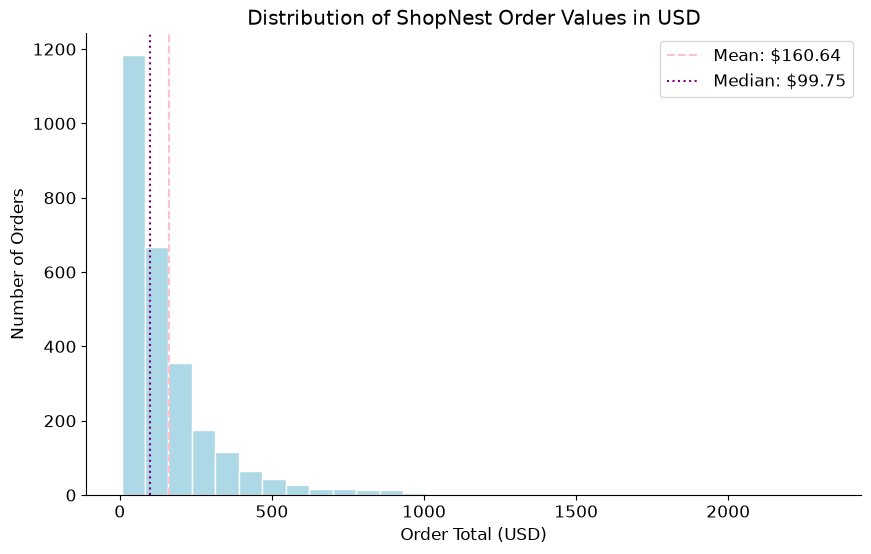

In [7]:
fig, ax = plt.subplots()
ax.hist(usd_orders["order_total"], bins=30,color="lightblue",edgecolor="white")
ax.axvline( mean_total,color="pink",linestyle="--",label=f"Mean: ${mean_total:.2f}")
ax.axvline(median_total,color="purple",linestyle=":",label=f"Median: ${median_total:.2f}")
ax.set_title("Distribution of ShopNest Order Values in USD")
ax.set_xlabel("Order Total (USD)")
ax.set_ylabel("Number of Orders")
ax.legend()
plt.show()

The distribution of USD order values is right-skewed. Most orders have lower totals, while a smaller number of expensive orders creates a long right tail. The average order value is approximately 160.64, comepared with a median of 99.75. This difference suggests that expensive orders increase the average, making the median useful for describing a typical order.

**Bar Chart**

In [8]:
category_counts = clean_df["product_category"].value_counts()


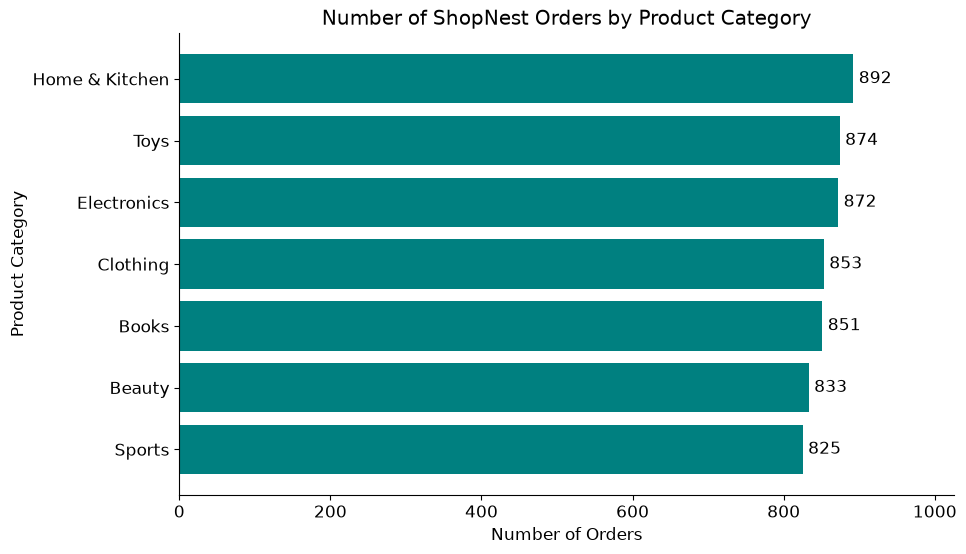

In [9]:
fig, ax = plt.subplots()
bars = ax.barh(category_counts.index[::-1],category_counts.values[::-1],color="teal")
# Annotate every bar with its count
ax.bar_label(bars, padding=4)
ax.set_title("Number of ShopNest Orders by Product Category")
ax.set_xlabel("Number of Orders")
ax.set_ylabel("Product Category")
# Leave room for the count labels
ax.set_xlim(0, category_counts.max() * 1.15)
plt.show()

Home & Kitchen has the most orders, with 892, while Sports has the fewest, with 825. The differences between categories are relatively small, suggesting that orders are fairly evenly distributed across product categories. These counts describe order frequency rather than revenue or the number of individual items sold.

 2. Use .groupby() and visualization to compare across categories

In [10]:
# Group orders by whether they were returned
delivery_summary = clean_df.groupby("returned").agg(average_delivery=("delivery_days", "mean"), valid_delivery_count=("delivery_days", "count"),total_orders=("order_id", "size"))
display(delivery_summary)


,average_delivery,valid_delivery_count,total_orders
returned,,,
No,6.671556,5386,5412
Yes,6.655822,584,588


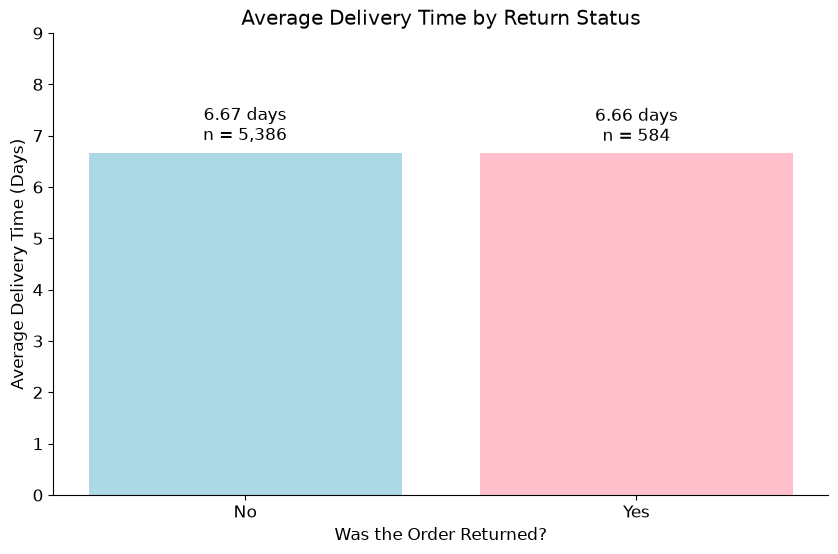

In [11]:
	
fig, ax = plt.subplots()
bars = ax.bar(delivery_summary.index,delivery_summary["average_delivery"],color=["lightblue", "pink"])

# Annotate the means and sample sizes
labels = [
    f"{mean:.2f} days\nn = {int(count):,}"
    for mean, count in zip(delivery_summary["average_delivery"],delivery_summary["valid_delivery_count"])]
ax.bar_label(bars, labels=labels, padding=5)
ax.set_title("Average Delivery Time by Return Status")
ax.set_xlabel("Was the Order Returned?")
ax.set_ylabel("Average Delivery Time (Days)")
ax.set_ylim(0, 9)
plt.show()

Returned and non-returned orders have almost identical average delivery times. Non-returned orders average approximately 6.67 days, while returned orders average approximately 6.66 days. This suggests that average delivery time does not clearly distinguish the two groups in this dataset. Other information, such as product quality or reasons for returns, would be needed to understand return behavior more fully.

# Section 2: Relationship Visualizations 

**Scatter Plot**

In [13]:
# Use orders with both delivery time and rating available
relationship_df = clean_df.dropna(
    subset=["delivery_days", "rating"])

In [14]:
# Calculate correlation using the original values
correlation = relationship_df["delivery_days"].corr(relationship_df["rating"])

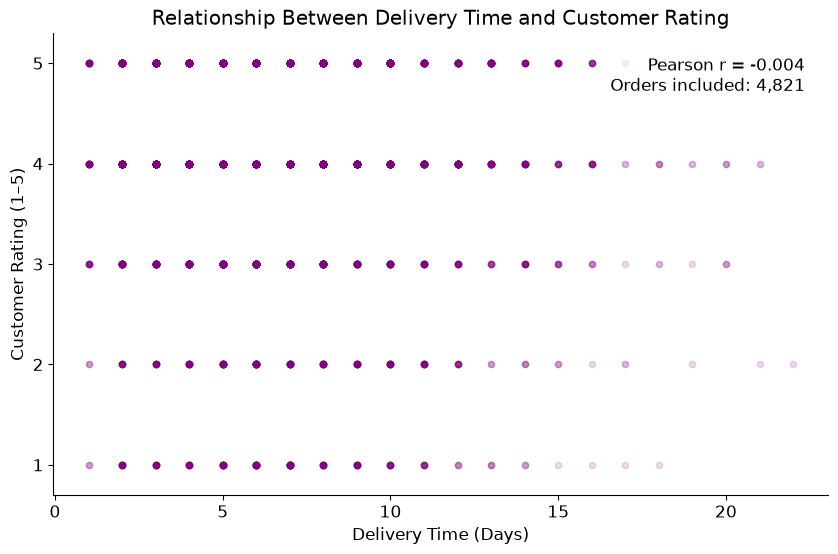

In [15]:
fig, ax = plt.subplots()
x_display = (relationship_df["delivery_days"])
y_display = (relationship_df["rating"])
ax.scatter(
    x_display,
    y_display,
    alpha=0.15,
    s=20,
    color="purple")
ax.set_title("Relationship Between Delivery Time and Customer Rating")
ax.set_xlabel("Delivery Time (Days)")
ax.set_ylabel("Customer Rating (1–5)")
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_ylim(0.7, 5.3)
ax.text( 0.97, 0.95, f"Pearson r = {correlation:.3f}\n"f"Orders included: {len(relationship_df):,}",transform=ax.transAxes, ha="right", va="top", bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "none"})
plt.show()

There is almost no linear relationship between delivery time and customer rating. The correlation is approximately −0.004, which is very close to zero. Ratings vary across delivery times without a clear upward or downward pattern. Some orders have unusually long delivery times, but these values alone do not establish errors. The analysis includes 4,821 orders with both variables available, so missing ratings may limit how well the results represent all customers.

**Heatmap of Correlations**

In [16]:
numerical_columns = ["items","order_total","delivery_days","rating"]
correlation_matrix = usd_orders[numerical_columns].corr()
display(correlation_matrix)

,items,order_total,delivery_days,rating
items,1.000000,0.498370,0.007001,0.012516
order_total,0.498370,1.000000,-0.013622,-0.034653
delivery_days,0.007001,-0.013622,1.000000,0.012895
rating,0.012516,-0.034653,0.012895,1.000000


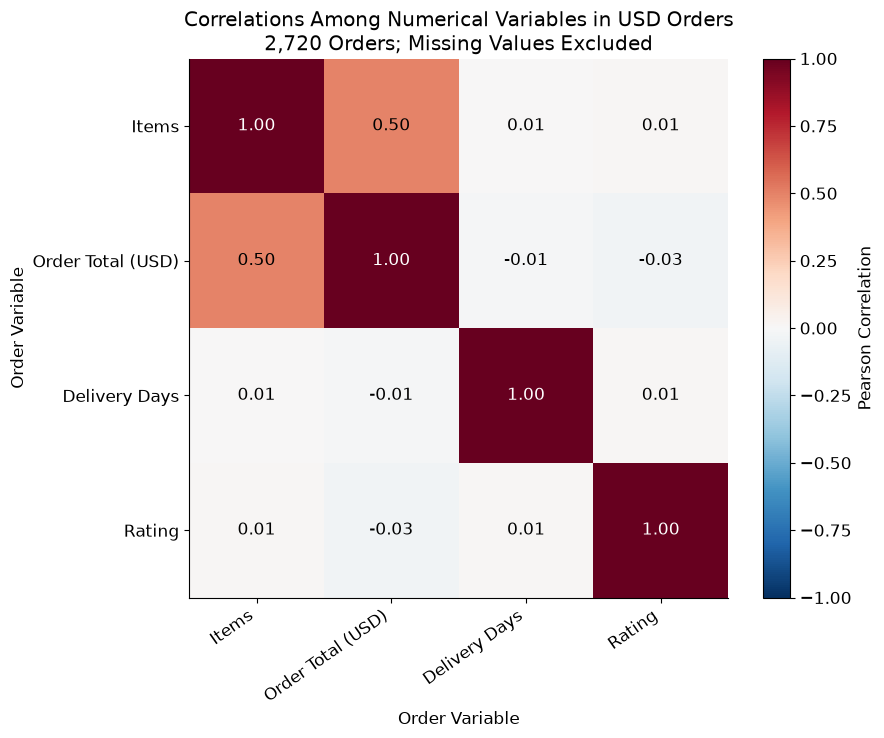

In [17]:
labels = ["Items","Order Total (USD)","Delivery Days","Rating"]
fig, ax = plt.subplots(figsize=(9, 7))
heatmap = ax.imshow(correlation_matrix, cmap="RdBu_r", vmin=-1,vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_yticklabels(labels)

# Annotate each cell with its correlation
for row in range(len(labels)):
    for column in range(len(labels)):
        value = correlation_matrix.iloc[row, column]

        ax.text(column,row,f"{value:.2f}",ha="center",va="center",color="white" if abs(value) > 0.6 else "black")

ax.set_title(f"Correlations Among Numerical Variables in USD Orders\n"f"{len(usd_orders):,} Orders; Missing Values Excluded")
ax.set_xlabel("Order Variable")
ax.set_ylabel("Order Variable")
fig.colorbar(heatmap, ax=ax, label="Pearson Correlation")
plt.show()

In [18]:
# Show how many observations contribute to each correlation
valid_values = usd_orders[numerical_columns].notna().astype(int)
pair_counts = valid_values.T.dot(valid_values)
display(pair_counts)

,items,order_total,delivery_days,rating
items,2720,2720,2698,2189
order_total,2720,2720,2698,2189
delivery_days,2698,2698,2698,2171
rating,2189,2189,2171,2189


The strongest relationship is between the number of items and order total, with a correlation of approximately 0.50. Orders containing more items tend to have higher totals. The remaining correlations are close to zero, suggesting weak linear relationships among those variables within USD orders. The table reports the number of available observations for each pair because missing ratings and delivery times reduce some sample sizes. These correlations describe associations and do not establish causation. 

# Summary and Conclusion

This analysis examined order distributions and relationships within the ShopNest dataset. Orders were fairly evenly distributed across product categories, while USD order values were right-skewed. Returned and non-returned orders had nearly identical average delivery times. Delivery time also showed almost no linear relationship with customer ratings. The clearest relationship was between the number of items purchased and the order total.Cleaning was important because duplicate rows, inconsistent country names, and invalid delivery times could affect the results. Missing ratings and limited information about how the dataset was collected also limit the conclusions. Further analysis could compare patterns within countries and product categories to identify differences that overall averages may hide.